# Task 11, Notebook 02: EDA, label analysis, leakage and skill/experience extraction

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 11: Rank resumes against job descriptions  
**Objective:** Explore the data, check the labels, hunt for leakage, then build and validate the skill and experience extractors.  
**Workflow stages covered in this notebook:** 14, 15, 16, 17, 18, 19, 20, 21 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3 | seed: 42


In [2]:
from cortexhr.phase3.common.io import read_csv
from cortexhr.phase3.resume import text as T
from cortexhr.phase3.common.validation import profile
resumes = read_csv('resumes'); jobs = read_csv('job_descriptions'); labels = read_csv('resume_job_labels'); pairs = read_csv('resume_bias_pairs')
dd = read_csv('data_dictionary')
print('resumes', resumes.shape, '| jobs', jobs.shape, '| labels', labels.shape, '| twin pairs', pairs.shape)

resumes (185, 15) | jobs (10, 11) | labels (555, 7) | twin pairs (25, 8)


## Stage 14: Exploratory Data Analysis (EDA)

*What this stage is for:* Look at the data before modelling.

Resumes come in several layouts (clean, tables, two-column, all caps, missing sections). Layout is the main reason text extraction can fail.

In [3]:
print(resumes.layout_difficulty.value_counts().to_dict()); print(resumes.source_format.value_counts().to_dict())
print(resumes.head(2)[['resume_id', 'target_job_family', 'total_experience_years', 'skills']])

{'Clean': 96, 'Two-column': 25, 'Tables': 25, 'Missing sections': 21, 'All-caps': 18}
{'PDF': 101, 'DOCX': 64, 'Plain text': 20}
  resume_id target_job_family  total_experience_years                                                                           skills
0  RES-0001               J04                     4.8  MLOps; Communication; TensorFlow; scikit-learn; PyTorch; Machine Learning; P...
1  RES-0002               J07                     3.7  Python; HR Policies; Leadership; Payroll Basics; HRIS; Time Management; Comm...


### Reading 5 resumes and 3 job descriptions, and what makes a good match

The cell below prints five resumes (different layouts) and three jobs. The list that follows is what the reading and the label analysis in stages 16 to 19 support.

In [4]:
for _, r in resumes.sample(5, random_state=SEED).iterrows(): print(f"{r.resume_id} | layout: {r.layout_difficulty} | {r.total_experience_years} yrs | skills: {r.skills}\n   {r.resume_text.split(chr(10))[2][:150]}")
print(); jobs[['job_id', 'job_title', 'min_experience_years', 'required_skills']].head(3)

RES-0020 | layout: Two-column | 4.0 yrs | skills: Regional Language Fluency; CRM; Communication; Customer Communication; MS Office; Zendesk; English Proficiency; User Research; Escalation Handling; Problem Solving; Python; Ticketing Tools
                                                   - Handled escalations and kept CSAT above 46%
RES-0043 | layout: Clean | 1.9 yrs | skills: Statistics; Content Marketing; SQL; Power BI; Recruitment; Leadership; Python; MS Office
   
RES-0157 | layout: Clean | 3.9 yrs | skills: Social Media Marketing; Content Marketing; Communication; User Research; B2B Sales; Critical Thinking; SEO; Email Campaigns
   
RES-0112 | layout: Two-column | 3.5 yrs | skills: User Research; Time Management; Python; Git; FastAPI; Docker; SQL; REST APIs; PostgreSQL; Critical Thinking
                                                   - Reduced API response time by 94% through query tuning
RES-0149 | layout: Missing sections | 1.6 yrs | skills: SQL; pandas; A/B Testing; Data V

  job_id                 job_title  min_experience_years                                       required_skills
0    J01         Software Engineer                     2          Python; SQL; REST APIs; Git; Data Structures
1    J02  Senior Software Engineer                     6  Python; System Design; REST APIs; PostgreSQL; Docker
2    J03              Data Analyst                     2    SQL; Excel; Python; Data Visualization; Statistics

**What makes a good match (from reading and from the data):** (1) the **required skills** of the job are actually evidenced in the text, not only listed; (2) the **role history** resembles the job (a Data Analyst reading for an Analyst opening); (3) **experience at or above the minimum** the job asks for, but not unlimited years; (4) nice-to-have skills help only after the required ones; (5) text similarity helps as a tie-breaker, not as the main signal. Name, gender, age and college tier are not on the list.

## Stage 15: Univariate Analysis

*What this stage is for:* One variable at a time.

One variable at a time: experience, number of skills, text length, minimum experience asked by jobs.

       total_experience_years  n_skills  text_len
count                  185.00    185.00    185.00
mean                     3.37      8.55    699.52
std                      2.24      2.32    271.52
min                      0.00      5.00    437.00
25%                      1.60      7.00    566.00
50%                      3.00      9.00    607.00
75%                      4.90     10.00    663.00
max                      9.30     14.00   1599.00

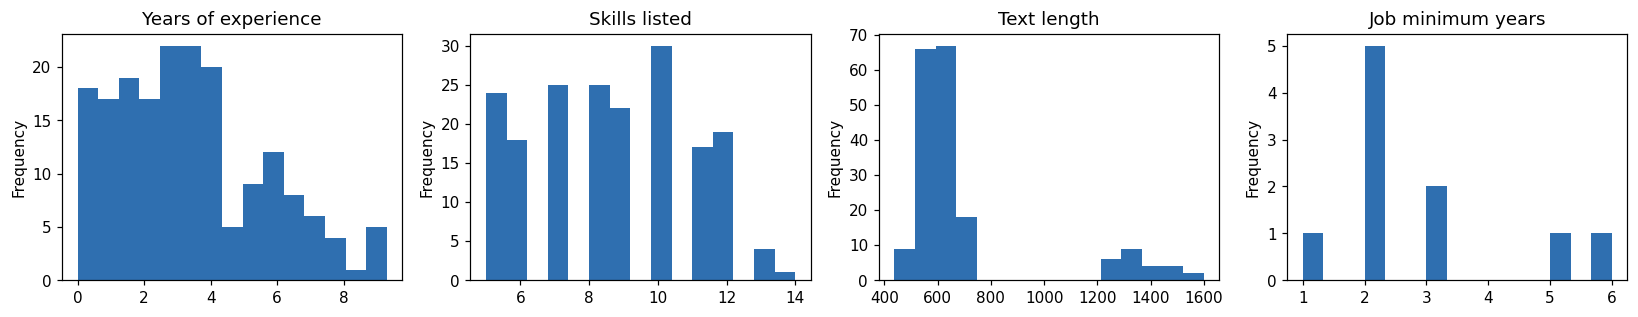

In [5]:
from cortexhr.phase3.resume.skills import split_skill_list
resumes['n_skills'] = resumes.skills.map(lambda s: len(split_skill_list(s))); resumes['text_len'] = resumes.resume_text.str.len()
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a, (c, t) in zip(ax, [('total_experience_years', 'Years of experience'), ('n_skills', 'Skills listed'), ('text_len', 'Text length'), ('min_experience_years', 'Job minimum years')]):
    (jobs if c == 'min_experience_years' else resumes)[c].plot.hist(ax=a, bins=15, color='#2f6fb0'); a.set_title(t)
plt.tight_layout(); resumes[['total_experience_years', 'n_skills', 'text_len']].describe().round(2)

## Stage 16: Bivariate Analysis

*What this stage is for:* Two variables together, especially against the target or label.

Two variables together: how do the human scores relate to the label file's own skill coverage and to experience?

human_suitability_score    1.000
required_skill_coverage    0.821
nice_skill_coverage        0.617
exp_gap                    0.346
Name: human_suitability_score, dtype: float64


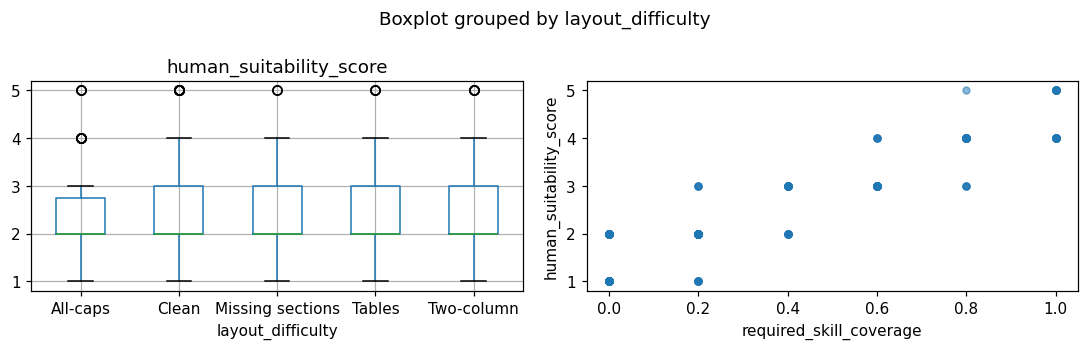

In [6]:
m = labels.merge(resumes[['resume_id', 'total_experience_years', 'layout_difficulty']], on='resume_id').merge(jobs[['job_id', 'min_experience_years']], on='job_id')
m['exp_gap'] = m.total_experience_years - m.min_experience_years
print(m[['human_suitability_score', 'required_skill_coverage', 'nice_skill_coverage', 'exp_gap']].corr(method='spearman').round(3)['human_suitability_score'])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2)); m.boxplot('human_suitability_score', 'layout_difficulty', ax=ax[0]); m.plot.scatter('required_skill_coverage', 'human_suitability_score', alpha=.3, ax=ax[1]); plt.tight_layout()

## Stage 17: Multivariate Analysis

*What this stage is for:* Several variables together: correlation, interaction, redundancy.

Several variables together: are the possible ranking signals redundant?

                         human_suitability_score  required_skill_coverage  nice_skill_coverage  total_experience_years  exp_gap
human_suitability_score                     1.00                     0.82                 0.62                    0.30     0.35
required_skill_coverage                     0.82                     1.00                 0.52                    0.09     0.13
nice_skill_coverage                         0.62                     0.52                 1.00                    0.21     0.18
total_experience_years                      0.30                     0.09                 0.21                    1.00     0.82
exp_gap                                     0.35                     0.13                 0.18                    0.82     1.00

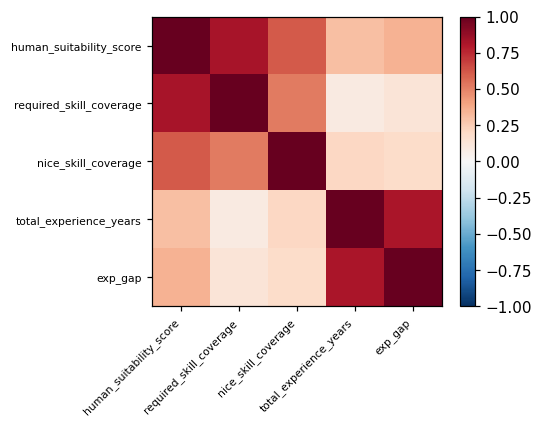

In [7]:
c = m[['human_suitability_score', 'required_skill_coverage', 'nice_skill_coverage', 'total_experience_years', 'exp_gap']].corr(method='spearman')
fig, ax = plt.subplots(figsize=(5, 4)); im = ax.imshow(c, cmap='RdBu_r', vmin=-1, vmax=1); ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=45, ha='right', fontsize=7); ax.set_yticks(range(len(c))); ax.set_yticklabels(c.columns, fontsize=7); plt.colorbar(im); plt.tight_layout(); c.round(2)

## Stage 18: Target or Label Analysis

*What this stage is for:* How the target or human label is distributed and how reliable it is.

The label is a human suitability score 1 to 5; `shortlist = Y` means 4 or 5. How many relevant candidates does each job have? This limits what recall@5 can show.

In [8]:
print(labels.human_suitability_score.value_counts().sort_index().to_dict()); print(labels.reviewer_note.value_counts().to_dict())
rel = labels.assign(rel=(labels.shortlist == 'Y')).groupby('job_id').agg(candidates=('rel', 'size'), relevant=('rel', 'sum')); rel['max_recall_at_5'] = (5 / rel.relevant).clip(upper=1).round(2); rel

{1: 106, 2: 274, 3: 80, 4: 72, 5: 23}
{'Weak match': 380, 'Strong match': 95, 'Partial match': 80}


        candidates  relevant  max_recall_at_5
job_id                                       
J01             64         7             0.71
J02             47         3             1.00
J03             60        12             0.42
J04             62        16             0.31
J05             57         9             0.56
J06             49         6             0.83
J07             49         8             0.62
J08             55         9             0.56
J09             57        14             0.36
J10             55        11             0.45

## Stage 19: Data Leakage Investigation

*What this stage is for:* Anything that carries the answer or protected information into the model.

Three leakage checks. (1) Does any resume column simply name the job it was written for? (2) Do label columns hide the answer? (3) Does the resume text carry protected information (name, e-mail, college tier)?

In [9]:
tj = labels.merge(resumes[['resume_id', 'target_job_family']], on='resume_id')
print('target_job_family == job_id among shortlisted pairs:', round((tj[tj.shortlist == 'Y'].target_job_family == tj[tj.shortlist == 'Y'].job_id).mean(), 3), '-> this column names the answer; it is NEVER used as a feature.')
print('label columns that are computed from skills and therefore must not be used as inputs:', ['required_skill_coverage', 'nice_skill_coverage'])
has_name = resumes.apply(lambda r: str(r.candidate_name).split()[0].lower() in r.resume_text.lower(), axis=1).mean(); has_mail = resumes.apply(lambda r: str(r.email).lower() in r.resume_text.lower(), axis=1).mean()
has_tier = resumes.resume_text.str.contains(r'\bTier\s*[1-9]', regex=True).mean()
pd.Series({'resume_text contains the candidate name': has_name, 'resume_text contains the e-mail': has_mail, 'resume_text contains a college tier phrase': has_tier}, name='share of resumes').round(3).to_frame()

target_job_family == job_id among shortlisted pairs: 1.0 -> this column names the answer; it is NEVER used as a feature.
label columns that are computed from skills and therefore must not be used as inputs: ['required_skill_coverage', 'nice_skill_coverage']


                                            share of resumes
resume_text contains the candidate name                1.000
resume_text contains the e-mail                        0.989
resume_text contains a college tier phrase             0.838

**Finding:** the free text carries name, e-mail and the college-tier phrase. Even if the structured columns are excluded, a model that reads `resume_text` as given still sees them. This is why the engine has a masking step and why Task 12 audits it.

## Stage 20: Feature Engineering

*What this stage is for:* Build the inputs the model will use from the raw data.

Build the two extractors and measure them against the structured columns (which are used only to *measure* the extractors, not to rank).

In [10]:
from cortexhr.phase3.resume.skills import SkillExtractor, build_vocabulary
from cortexhr.phase3.resume.experience import extract_experience
ext = SkillExtractor(build_vocabulary(jobs, resumes)); rows = []
for _, r in resumes.iterrows():
    clean = T.for_skill_extraction(r.resume_text, r.candidate_name, r.email, r.city); truth = {ext.canon(s) for s in split_skill_list(r.skills)}; got = set(ext.extract(clean))
    e = extract_experience(clean); rows.append({'resume_id': r.resume_id, 'layout': r.layout_difficulty, 'skill_recall': len(truth & got) / len(truth), 'skill_precision': len(truth & got) / max(1, len(got)),
        'years_extracted': e['total_years'], 'years_column': r.total_experience_years, 'exp_flags': ','.join(e['flags'])})
q = pd.DataFrame(rows); q['exp_abs_error'] = (q.years_extracted - q.years_column).abs()
print('skill recall %.3f | precision %.3f | resumes with years error > 0.15: %d of %d' % (q.skill_recall.mean(), q.skill_precision.mean(), (q.exp_abs_error > 0.15).sum(), len(q)))
q.groupby('layout')[['skill_recall', 'skill_precision', 'exp_abs_error']].mean().round(3)

skill recall 0.972 | precision 0.969 | resumes with years error > 0.15: 0 of 185


                  skill_recall  skill_precision  exp_abs_error
layout                                                        
All-caps                  1.00            0.940            0.0
Clean                     1.00            0.974            0.0
Missing sections          0.75            0.979            0.0
Tables                    1.00            0.967            0.0
Two-column                1.00            0.960            0.0

In [11]:
low = q.sort_values('skill_recall').head(3); print('lowest skill recall (text has fewer skills than the structured list):'); low[['resume_id', 'layout', 'skill_recall']]

lowest skill recall (text has fewer skills than the structured list):


    resume_id            layout  skill_recall
11   RES-0012  Missing sections      0.363636
117  RES-0118  Missing sections      0.375000
164  RES-0165  Missing sections      0.375000

Low recall appears for resumes with *missing sections*: the text simply does not mention all listed skills, so no text method can find them. That is a data limit, reported, not hidden.

**Think for yourself: would I rank on years of experience alone? No.** Years alone favours people with long, uninterrupted careers and disadvantages career changers, people returning after a break (more often women), and younger candidates. It also says nothing about *which* skills were used. In this engine experience is one capped part of the score (20%); notebook 03 shows how weak 'experience only' is as a ranker.

## Stage 21: Feature Selection and Relevance Analysis

*What this stage is for:* Which inputs are allowed, which are relevant, which must never be used.

Which inputs may enter the score, which are relevant, and which are forbidden.

In [12]:
from cortexhr.phase3.resume.scoring import FORBIDDEN_SCORE_INPUTS
print('FORBIDDEN as score inputs:', list(FORBIDDEN_SCORE_INPUTS))
print('ALLOWED: masked resume text (TF-IDF), skills found in the text vs job skills, years of experience found in the text vs the job minimum')
f = labels.merge(resumes[['resume_id', 'total_experience_years']], on='resume_id').merge(jobs[['job_id', 'min_experience_years']], on='job_id')
f['exp_fit'] = (f.total_experience_years / f.min_experience_years.clip(lower=1)).clip(upper=1)
pd.Series({'required skill coverage (label file, for orientation only)': f.human_suitability_score.corr(f.required_skill_coverage, method='spearman'), 'experience fit': f.human_suitability_score.corr(f.exp_fit, method='spearman')}, name='spearman with human score').round(3).to_frame()

FORBIDDEN as score inputs: ['candidate_name', 'email', 'gender', 'age', 'college_tier', 'city', 'target_job_family']
ALLOWED: masked resume text (TF-IDF), skills found in the text vs job skills, years of experience found in the text vs the job minimum


                                                            spearman with human score
required skill coverage (label file, for orientation only)                      0.821
experience fit                                                                  0.363